# Transient Debye-Waller Effect

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/08-xray_diffraction/03-transient_debye_waller.ipynb)

In this example the transient Debye-Waller effect is simulated, i.e. the change of the X-ray scattering intensity due to a change of the temperature of the sample.
As for the thermal properties, the `deb_wal_fac` property of a {py:class}`Layer <udkm1Dsim.structures.layers.Layer>` can have multiple elements, which are assigned to the temperatures of different sub-systems of the sample.

:::{versionadded} 2.3.0
Temperature-dependence of Debye-Waller factor with example {py:class}`XrayDyn <udkm1Dsim.simulations.scattering.dynamical.XrayDyn>`
:::

:::{admonition} Reference {cite}`pudell2026`
:class: seealso
J.-E. Pudell, et al., *Ultrafast x-ray thermometry: Contrasting strain and Debye-Waller effects in platinum thin films*, [Phys. Rev. B 113, L220301 (2026)](https://doi.org/10.1103/x46h-3kdb) 
:::

Refer to the [dynamical X-ray scattering example](#example_dynamical_xray) for more details on the strain-dependent scattering.

## Setup

Do all necessary imports and settings.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim[parallel]
    import udkm1Dsim as ud

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

## Structure

Refer to the [structure example](#example_structure) for more details.

In [2]:
Mg = ud.Atom("Mg")
O = ud.Atom("O")
Pt = ud.Atom("Pt")

In [3]:
# c-axis lattice constants
c_Pt = 0.22649 * u.nm
c_MgO = 0.421272 * u.nm

# Platinum layer
Pt_sub_system_coupling_formula = (
    "-7.09e-3*T_0**5 +3.64e2*T_0**4-7.30e6*T_0**3+7.29e10*T_0**2-3.85e14*T_0+12.046e17"
)
Pt_layer = ud.UnitCell(
    "Pt",
    "Platinum",
    lattice=ud.LatticeParameters(a_axis=c_Pt, b_axis=c_Pt / 0.77, c_axis=c_Pt),
    thermal=ud.ThermalParameters(
        heat_capacity=[
            "740/21450*T",
            "(23.8992 +7.89939e-3*T -3.77463e-6*T**2+ 1.53451e-9*T**3 -27697.5/(T**2))"
            "/(195.084/1000.0)",
        ],
        therm_cond=["(71-5)*(T_0/T_1)", 5 * u.W / (u.m * u.K)],
        sub_system_coupling=[
            f"-0.5*({Pt_sub_system_coupling_formula:s})*(T_0-T_1)",
            f"-0.5*({Pt_sub_system_coupling_formula:s})*(T_1-T_0)",
        ],
        lin_therm_exp=[
            "2.22e-9*T",
            "(1.300e-13*T**5 + -4.176e-10*T**4 + 5.179e-07*T**3 "
            "- 3.088e-04*T**2 + 9.093e-02*T + 9.343e+00)*1e-6 - 2.22e-9*T",
        ],
        deb_wal_fac=[
            "0",
            "(0.02938 + 0.1090e-2*T + 0.4310e-6*(T**2) - 0.4681e-9*(T**3) "
            "+ 0.1829e-12*(T**4))/(8*pi**2)*1e-20",
        ],
        sub_system_labels=["e", "p"],  # electrons and phonons
    ),
    elastic=ud.ElasticParameters(sound_vel=3.95 * u.nm / u.ps),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(2.55 + 6.35j)),
)
Pt_layer.add_atom(Pt, 0)

# MgO substrate
MgO_sub = ud.UnitCell(
    "MgO",
    "MgO",
    lattice=ud.LatticeParameters(c_axis=c_MgO),
    thermal=ud.ThermalParameters(
        heat_capacity=[0.00001, 877],
        therm_cond=[0, "2.42e4 * (T**-1.114) /1.25"],
        sub_system_coupling=["-1.0e17*(T_0-T_1)", "1.0e17*(T_0-T_1)"],
        lin_therm_exp=[
            0,
            "1.61*(1.664e-13*T**5 + -5.689e-10*T**4"
            "+ 7.591e-07*T**3 + -4.935e-04*T**2 + 1.633e-01*T"
            "+ -1.033e+01)*1e-6",
        ],
        deb_wal_fac=[0, 0],
        sub_system_labels=["e", "p"],
    ),
    elastic=ud.ElasticParameters(sound_vel=9.12 * u.nm / u.ps),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(1.7222)),
)
MgO_sub.add_atom(Mg, 0)
MgO_sub.add_atom(O, 0)
MgO_sub.add_atom(Mg, 0)
MgO_sub.add_atom(O, 0)
MgO_sub.add_atom(Mg, 0.5)
MgO_sub.add_atom(O, 0.5)
MgO_sub.add_atom(Mg, 0.5)
MgO_sub.add_atom(O, 0.5)

Pt_layer.thermal

Thermal Parameters
╔═════════════════════╦══════════╦══════════════════════════════════════════════════════════════════════════════════════════════════╦════════╗
║ Parameter           ║  Symbol  ║                                                                                            Value ║ Unit   ║
╠═════════════════════╬══════════╬══════════════════════════════════════════════════════════════════════════════════════════════════╬════════╣
║ therm_cond          ║    κₑ    ║                                                                                         66·Tₑ/Tₚ ║ W/K/m  ║
║                     ║    κₚ    ║                                                                                                5 ║        ║
╠═════════════════════╬══════════╬══════════════════════════════════════════════════════════════════════════════════════════════════╬════════╣
║ heat_capacity       ║    cₑ    ║                                                                                       74·Tₑ/2145 ║ J/K/kg ║
║                     ║    cₚ    ║                              7.866×10⁻⁹·Tₚ³ − 1.935×10⁻⁵·Tₚ² + 0.04049·Tₚ + 122.5 − 1.42×10⁵/Tₚ² ║        ║
╠═════════════════════╬══════════╬══════════════════════════════════════════════════════════════════════════════════════════════════╬════════╣
║ lin_therm_exp       ║    αₑ    ║                                                                                     2.22×10⁻⁹·Tₑ ║        ║
║                     ║    αₚ    ║ 1.3×10⁻¹⁹·Tₚ⁵ − 4.176×10⁻¹⁶·Tₚ⁴ + 5.179×10⁻¹³·Tₚ³ − 3.088×10⁻¹⁰·Tₚ² + 8.871×10⁻⁸·Tₚ + 9.343×10⁻⁶ ║        ║
╠═════════════════════╬══════════╬══════════════════════════════════════════════════════════════════════════════════════════════════╬════════╣
║ sub_system_coupling ║    Gₑ    ║  (Tₑ − Tₚ)·(0.003545·Tₑ⁵ − 182·Tₑ⁴ + 3.65×10⁶·Tₑ³ − 3.645×10¹⁰·Tₑ² + 1.925×10¹⁴·Tₑ − 6.023×10¹⁷) ║ W/m³   ║
║                     ║    Gₚ    ║ (−Tₑ + Tₚ)·(0.003545·Tₑ⁵ − 182·Tₑ⁴ + 3.65×10⁶·Tₑ³ − 3.645×10¹⁰·Tₑ² + 1.925×10¹⁴·Tₑ − 6.023×10¹⁷) ║        ║
╠═════════════════════╬══════════╬══════════════════════════════════════════════════════════════════════════════════════════════════╬════════╣
║ deb_wal_fac         ║  ⟨u²⟩ₑ   ║                                                                                                0 ║ m²     ║
║                     ║  ⟨u²⟩ₚ   ║        1.25×10⁻²¹·(1.829×10⁻¹³·Tₚ⁴ − 4.681×10⁻¹⁰·Tₚ³ + 4.31×10⁻⁷·Tₚ² + 0.00109·Tₚ + 0.02938)/pi² ║        ║
╠═════════════════════╬══════════╬══════════════════════════════════════════════════════════════════════════════════════════════════╬════════╣
║ num_sub_systems     ║    N     ║                                                                                                2 ║        ║
╚═════════════════════╩══════════╩══════════════════════════════════════════════════════════════════════════════════════════════════╩════════╝

:::{attention}
The number of elements of the `deb_wal_fac` property is not checked and must not be equal to `num_sub_system`.
This helps for backwards compatibility and decouples {py:class}`Heat <udkm1Dsim.simulations.heat.Heat>` and {py:class}`XrayDyn <udkm1Dsim.simulations.scattering.dynamical.XrayDyn>` simulations.
:::

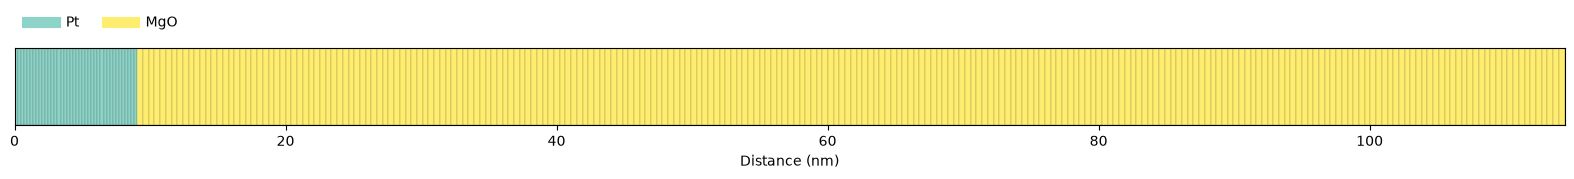

times,sub-structure,thickness
40,Platinum,9.06 nm
250,MgO,105.3 nm


In [4]:
S = ud.Structure("Pt on MgO substrate")

S.add_sub_structure(Pt_layer, 40)
S.add_sub_structure(MgO_sub, 250)

# add semi-infinite, static substrate
S.add_substrate(MgO_sub)

S.visualize()
S

## Heat

Refer to the [excitation & NTM example](#example_excitation_NTM) for more details.

In [5]:
h = ud.Heat(S, True)

h.save_data = False
h.disp_messages = True

h.excitation = {
    "fluence": [5] * u.mJ / u.cm**2,
    "delay_pump": [0] * u.ps,
    "pulse_width": [0.6] * u.ps,
    "multilayer_absorption": True,
    "polarization": "p",
    "wavelength": 1030 * u.nm,
    "theta": 55 * u.deg,
}

# enable heat diffusion
h.heat_diffusion = True

init_temp = 450
# set the boundary conditions
h.boundary_conditions = {
    "top_type": "isolator",
    "bottom_type": "temperature",
    "bottom_value": [init_temp, init_temp] * u.K,
}

# temporal and spatial grid
delays = np.r_[-10:-1:3, -1:5:0.25, np.logspace(np.log10(5), np.log10(500), num=50)] * u.ps
_, _, distances = S.layer_distances

### Laser Absorption Profile

Absorption profile is calculated by multilayer formalism with p-polarization.
Total reflectivity of 35.8 % and transmission of 31.7 %.


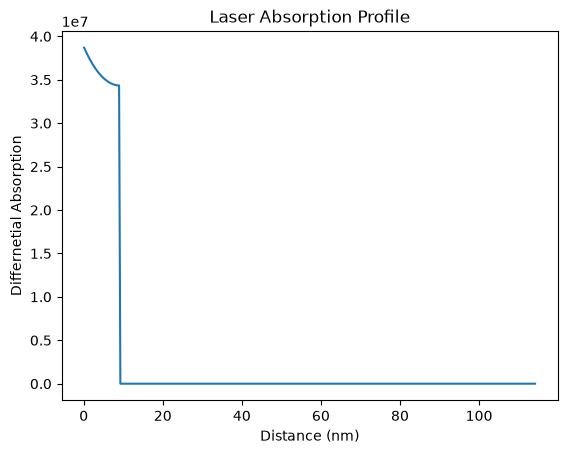

In [6]:
plt.figure()
dAdz, _, _, _ = h.get_multilayers_absorption_profile()
plt.plot(distances.to("nm"), dAdz)
plt.xlabel("Distance (nm)")
plt.ylabel("Differnetial Absorption")
plt.title("Laser Absorption Profile")
plt.show()

### Temperature Map

In [7]:
res_temp = h.get_temp_map(delays, init_temp * u.K)

Surface incidence fluence scaled by factor 0.8192 due to incidence angle theta=55.00 deg
Calculating _heat_diffusion_ without excitation...


0it [00:00, ?it/s]

Elapsed time for _heat_diffusion_: 0.029346 s
Calculating _heat_diffusion_ for excitation 1:1 ...
Absorption profile is calculated by multilayer formalism with p-polarization.
Total reflectivity of 35.8 % and transmission of 31.7 %.


0it [00:00, ?it/s]

Elapsed time for _heat_diffusion_ with 1 excitation(s): 0.094286 s
Calculating _heat_diffusion_ without excitation...


0it [00:00, ?it/s]

Elapsed time for _heat_diffusion_: 0.057224 s
Elapsed time for _temp_map_: 0.242137 s


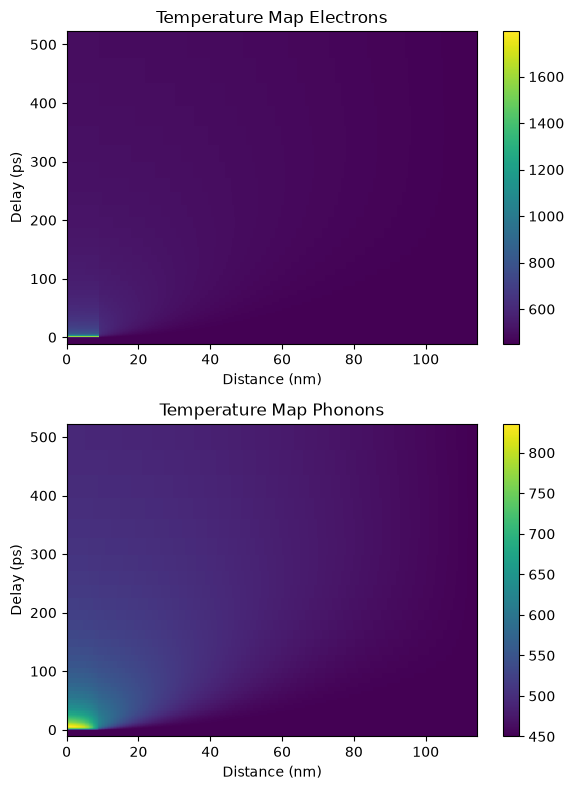

In [8]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
plt.pcolormesh(
    res_temp.quantity("distances", "nm"),
    res_temp.quantity("delays", "ps"),
    res_temp.temp_map[:, :, 0],
    shading="auto",
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Temperature Map Electrons")

plt.subplot(2, 1, 2)
plt.pcolormesh(
    res_temp.quantity("distances", "nm"),
    res_temp.quantity("delays", "ps"),
    res_temp.temp_map[:, :, 1],
    shading="auto",
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Temperature Map Phonons")

plt.tight_layout()
plt.show()

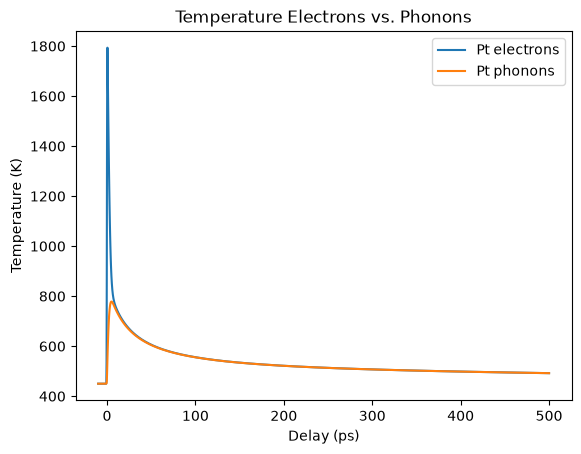

In [9]:
plt.figure()
select_Pt = S.positions_per_unique_layer["Pt"]
plt.plot(
    res_temp.quantity("delays", "ps"),
    np.mean(res_temp.temp_map[:, select_Pt, 0], 1),
    label="Pt electrons",
)
plt.plot(
    res_temp.quantity("delays", "ps"),
    np.mean(res_temp.temp_map[:, select_Pt, 1], 1),
    label="Pt phonons",
)
plt.ylabel("Temperature (K)")
plt.xlabel("Delay (ps)")
plt.legend()
plt.title("Temperature Electrons vs. Phonons")
plt.show()

## Numerical Phonons

Refer to the [strain pulse example](#example_strain_pulses) for more details.

In [10]:
p = ud.PhononNum(S, True)
p.save_data = False
p.disp_messages = True

:::{Attention}
Here, only the thermal expansion is calculated, but no coherent acoustic phonons, i.e. sound waves.
:::

In [11]:
p.only_heat = True

In [12]:
res_strain = p.get_strain_map(delays, res_temp)

Calculating linear thermal expansion ...
Elapsed time for _strain_map_: 0.051960 s


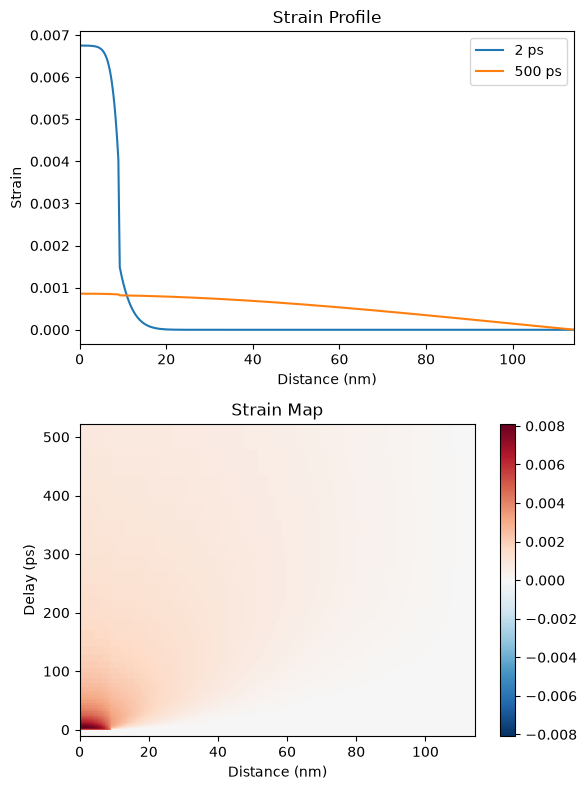

In [13]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
plt.plot(
    res_strain.quantity("distances", "nm"),
    res_strain.strain_map[13, :],
    label=np.round(res_strain.quantity("delays", "ps")[13]),
)
plt.plot(
    res_strain.quantity("distances", "nm"),
    res_strain.strain_map[-1, :],
    label=np.round(res_strain.quantity("delays", "ps")[-1]),
)
plt.xlim([0, res_strain.quantity("distances", "nm")[-1]])
plt.xlabel("Distance (nm)")
plt.ylabel("Strain")
plt.legend()
plt.title("Strain Profile")

plt.subplot(2, 1, 2)
plt.pcolormesh(
    res_strain.quantity("distances", "nm"),
    res_strain.quantity("delays", "ps"),
    res_strain.strain_map,
    cmap="RdBu_r",
    vmin=-np.max(res_strain.strain_map),
    vmax=np.max(res_strain.strain_map),
    shading="auto",
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Strain Map")

plt.tight_layout()
plt.show()

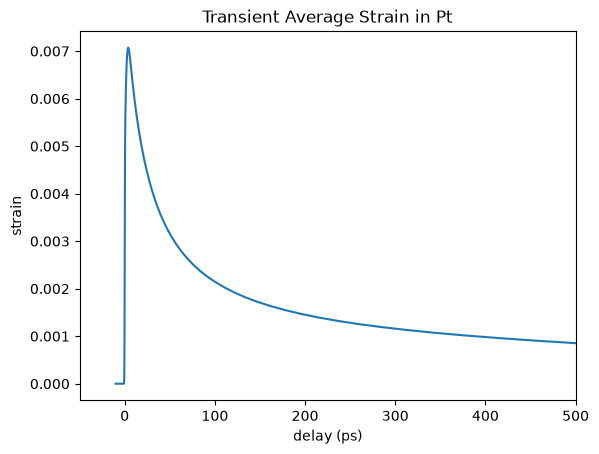

In [14]:
plt.figure()
plt.plot(res_strain.quantity("delays", "ps"), np.mean(res_strain.strain_map[:, select_Pt], 1))
plt.ylabel("strain")
plt.xlabel("delay (ps)")
plt.xlim([-50, 500])
plt.title("Transient Average Strain in Pt")
plt.show()

## Initialize dynamical X-ray simulation

In [15]:
dyn = ud.XrayDyn(S, True)
dyn.disp_messages = True
dyn.save_data = False

## Homogeneous X-ray scattering

For the case of homogeneously strained and/or heated samples, the dynamical X-ray scattering simulations can be greatly simplified, which saves a lot of computational time.

:::{attention}
For a temperature-dependent `deb_wal_fac` property, {py:class}`XrayDyn <udkm1Dsim.simulations.scattering.dynamical.XrayDyn>` simulations are carried out at 0 K by default.
Other temperatures can be given to both `homogeneous_reflectivity` and `inhomogeneous_reflectivity`, see below.
:::

Calculating _homogeneous_reflectivity_ ...
Elapsed time for _homogeneous_reflectivity_: 0.020684 s


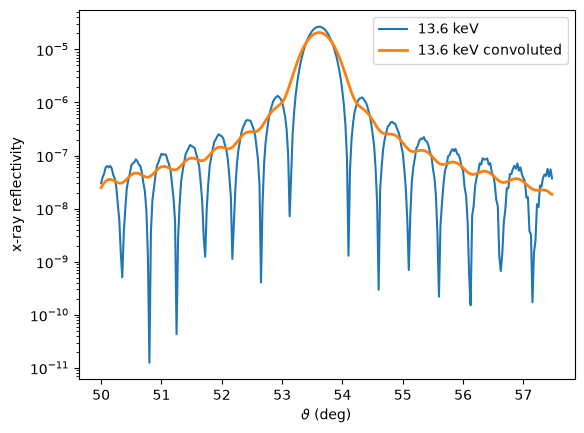

In [16]:
dyn.energy = np.r_[13600] * u.eV  # set photon energy
dyn.theta = np.r_[50:57.5:0.025] * u.degree  # set theta range

res_hom = dyn.homogeneous_reflectivity()

# instrument function / mosaicity of sample
FWHM = 0.05 / 1e-10  # Angstrom
sigma = FWHM / 2.3548


def handle(x):
    return np.exp(-(((x) / sigma) ** 2) / 2)


y_conv = dyn.conv_with_function(
    res_hom.R[0, :], res_hom.quantity("qz", "1/m").magnitude[0, :], handle
)

plt.figure()
plt.semilogy(
    res_hom.theta[0, :],
    res_hom.R[0, :],
    label="{}".format(res_hom.quantity("energy", "keV")[0]),
)
plt.semilogy(
    res_hom.theta[0, :],
    y_conv,
    label="{} convoluted".format(res_hom.quantity("energy", "keV")[0]),
    lw=2,
)
plt.ylabel("x-ray reflectivity")
plt.xlabel(r"$\vartheta$ (deg)")
plt.legend()
plt.show()

Here, strains and temperatures can already be applied, but only as an average value per layer.

Calculating _homogeneous_reflectivity_ ...
Elapsed time for _homogeneous_reflectivity_: 0.027571 s
Calculating _homogeneous_reflectivity_ ...
Elapsed time for _homogeneous_reflectivity_: 0.017643 s
Calculating _homogeneous_reflectivity_ ...
Elapsed time for _homogeneous_reflectivity_: 0.017647 s


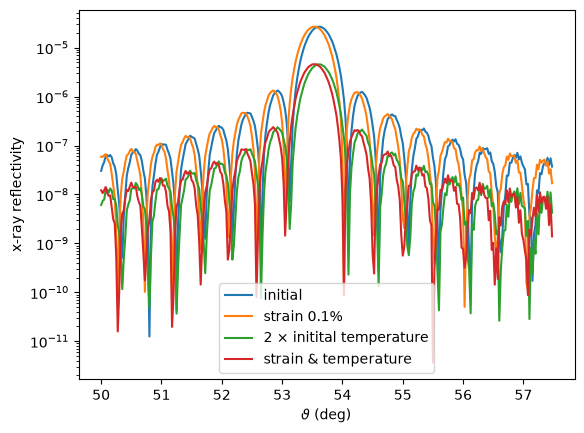

In [17]:
plt.figure()
plt.semilogy(res_hom.theta[0, :], res_hom.R[0, :], label="initial")

res_hom = dyn.homogeneous_reflectivity(strains=[0.001, 0.001])
plt.semilogy(res_hom.theta[0, :], res_hom.R[0, :], label="strain 0.1%")

res_hom = dyn.homogeneous_reflectivity(temps=np.array([[0, 2 * init_temp], [0, 0]]))
plt.semilogy(res_hom.theta[0, :], res_hom.R[0, :], label=r"2 $\times$ initital temperature")

res_hom = dyn.homogeneous_reflectivity(
    strains=[0.001, 0.001], temps=np.array([[0, 2 * init_temp], [0, 0]])
)
plt.semilogy(res_hom.theta[0, :], res_hom.R[0, :], label=r"strain & temperature")

plt.ylabel("x-ray reflectivity")
plt.xlabel(r"$\vartheta$ (deg)")
plt.legend()
plt.show()

## Inhomogeneous X-ray scattering

For this simulation, the `strain_vectors` cannot be used to speed up the calculation.
Hence, it is beneficial to run this simulation in `parallel` mode.

In [18]:
try:
    from dask.distributed import Client

    client = Client(threads_per_worker=1)  # one worker per CPU core
    res_seq = dyn.inhomogeneous_reflectivity(
        res_strain, temp_map=res_temp, calc_type="parallel", dask_client=client
    )
except ImportError:
    res_seq = dyn.inhomogeneous_reflectivity(res_strain, temp_map=res_temp, calc_type="sequential")

Calculating _inhomogeneous_reflectivity_dyn_ ...


Progress:   0%|          | 0/77 [00:00<?, ?it/s]

Elapsed time for _inhomogeneous_reflectivity_dyn_: 20.858778 s


The experimental resolution is included by a convolution.

In [19]:
R_seq_conv = np.zeros_like(res_seq.R)
for i in range(len(res_seq.delays)):
    R_seq_conv[i, 0, :] = dyn.conv_with_function(
        res_seq.R[i, 0, :], res_seq.quantity("qz", "1/m").magnitude[0, :], handle
    )

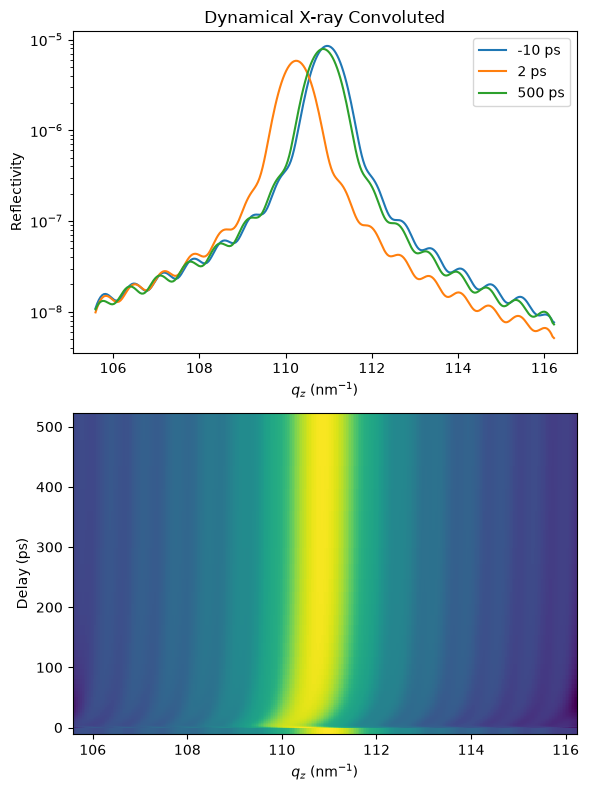

In [20]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
plt.semilogy(
    res_seq.quantity("qz", "1/nm")[0, :],
    R_seq_conv[0, 0, :],
    label=np.round(res_seq.quantity("delays", "ps")[0]),
)
plt.semilogy(
    res_seq.quantity("qz", "1/nm")[0, :],
    R_seq_conv[13, 0, :],
    label=np.round(res_seq.quantity("delays", "ps")[13]),
)
plt.semilogy(
    res_seq.quantity("qz", "1/nm")[0, :],
    R_seq_conv[-1, 0, :],
    label=np.round(res_seq.quantity("delays", "ps")[-1]),
)

plt.xlabel("$q_z$ (nm$^{-1}$)")
plt.ylabel("Reflectivity")
plt.legend()
plt.title("Dynamical X-ray Convoluted")

plt.subplot(2, 1, 2)
plt.pcolormesh(
    res_seq.qz[0, :],
    res_seq.quantity("delays", "ps"),
    np.log10(R_seq_conv[:, 0, :]),
    shading="auto",
)
plt.ylabel("Delay (ps)")
plt.xlabel("$q_z$ (nm$^{-1}$)")

plt.tight_layout()
plt.show()

Extract the relative integrated peak intensity of the Pt layer due to the transient Debye-Waller effect.

Text(0.5, 0, 'Delay (ps)')

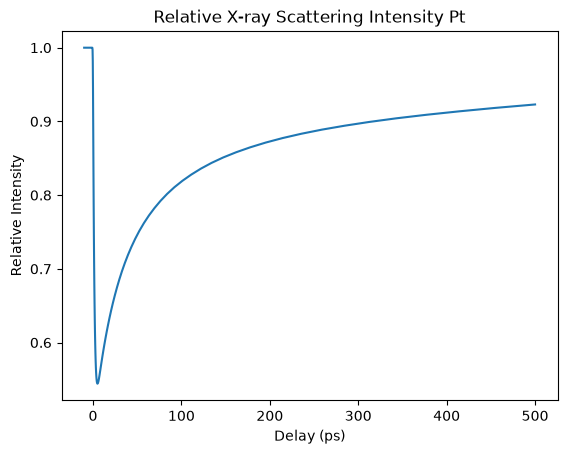

In [21]:
plt.figure()
plt.plot(
    res_seq.quantity("delays", "ps"),
    np.sum(R_seq_conv[:, 0, :], axis=1) / np.sum(R_seq_conv[0, 0, :]),
)
plt.title("Relative X-ray Scattering Intensity Pt")
plt.ylabel("Relative Intensity")
plt.xlabel("Delay (ps)")

## Gallery Plot

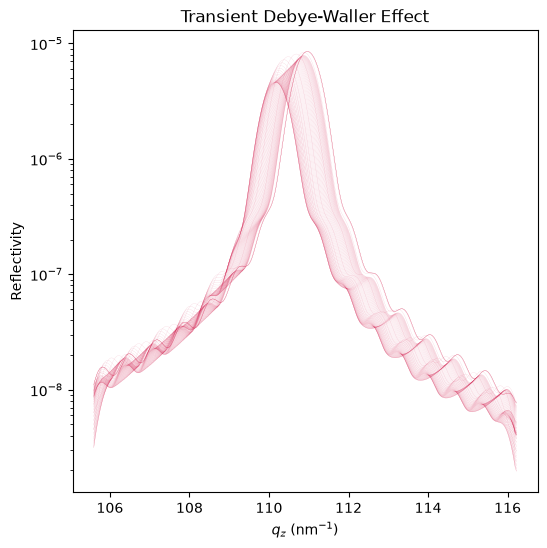

In [22]:
plt.figure(figsize=[6, 6])

for i in range(len(res_seq.delays)):
    plt.semilogy(
        res_seq.quantity("qz", "1/nm")[0, :],
        R_seq_conv[i, 0, :],
        color="#D71045",
        alpha=0.25,
        lw=0.15,
    )

plt.xlabel("$q_z$ (nm$^{-1}$)")
plt.ylabel("Reflectivity")
plt.title("Transient Debye-Waller Effect")
plt.show()